# Bedside Anaemia Risk Estimator

**Use case.** In a rural clinic with no laboratory, a nurse cannot measure a child's haemoglobin, so severe anaemia can go unseen. This notebook builds a model that estimates haemoglobin (hb, in g/dL) from signs a nurse can check at the bedside, so the children with the lowest estimates can be referred first.

**Who uses the prediction, and for what.** Nurses and clinical officers in clinics without lab access use the estimate to rank sick children for referral and possible transfusion.

**Mission link.** Improving access to timely care in low resource health settings.

**Dataset.** Admission records for 29,226 children at Kilifi County Hospital, Kenya (2002 to 2009), 31 columns, a mix of numeric and categorical variables. Public domain (CC0).
Maitland K, Ohuma EO, Mpoya A, Uyoga S, Hassall O, Williams TN (2019). Figshare. https://doi.org/10.6084/m9.figshare.7635908.v1

**Target.** `hb`, the haemoglobin at admission in g/dL, a continuous number.

**Plan.** Explore the data, clean it, split it, compare four regression models on the same test set, save the best one as a Pipeline, and predict for one test row.

## 1. Setup

The library versions are pinned to match the uv environment in the repository, so the model saved here loads correctly in the API on Render.

In [28]:
!pip install -q scikit-learn==1.9.1

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Informing_Thresholds_for_paediatric_transfusion_in_Africa.csv", sep="\t")
print(df.shape)

(29226, 31)


The file is tab separated even though it ends in `.csv`, so it is read with `sep="\t"`. It has 29,226 rows and 31 columns, which meets the requirement of at least 1,000 rows and 8 feature columns.

## 2. Explore the data

In [30]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique()
})
summary

,dtype,missing,unique
sex,str,0,2
temp_gradient,str,115,2
pallor,str,45,2
indrawing,str,43,2
resp_deep,str,46,2
hb,float64,0,181
age_months,float64,0,3997
fever_high,str,56,2
waz_low,float64,216,2
died,str,0,2


**What it shows.** Each column with its type, missing values and unique values. `hiv_cat` (17,974 missing) and `base_def_8` (12,819 missing) are mostly empty, and `conscious_group` is missing 3,992. The yes/no columns are written in three different ways (`y/n`, `yes/no`, `Yes/No`).

**Decision.** Drop the mostly empty columns, and write one cleaning step that turns every yes/no style column into 1 and 0.

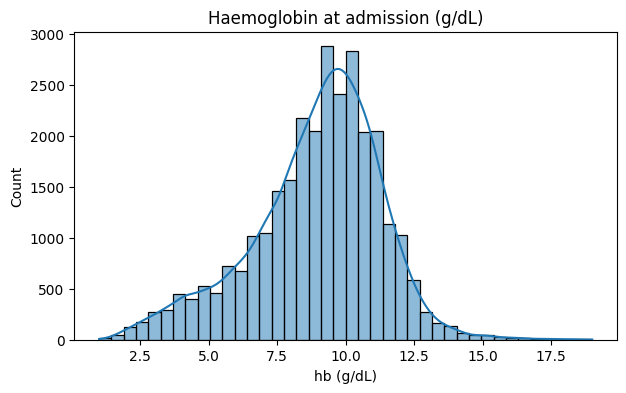

In [31]:
plt.figure(figsize=(7, 4))
sns.histplot(df["hb"], bins=40, kde=True)
plt.title("Haemoglobin at admission (g/dL)")
plt.xlabel("hb (g/dL)")
plt.show()

**What it shows.** Haemoglobin runs from 1 to 19 g/dL with a mean of about 8.9 and a median of about 9.3. The shape is roughly bell shaped with a mild skew to the left, caused by a long tail of children with very low haemoglobin.

**Decision.** Keep the low tail, because those are the children the tool most needs to find. Use mean squared error as the loss and leave `hb` untransformed.

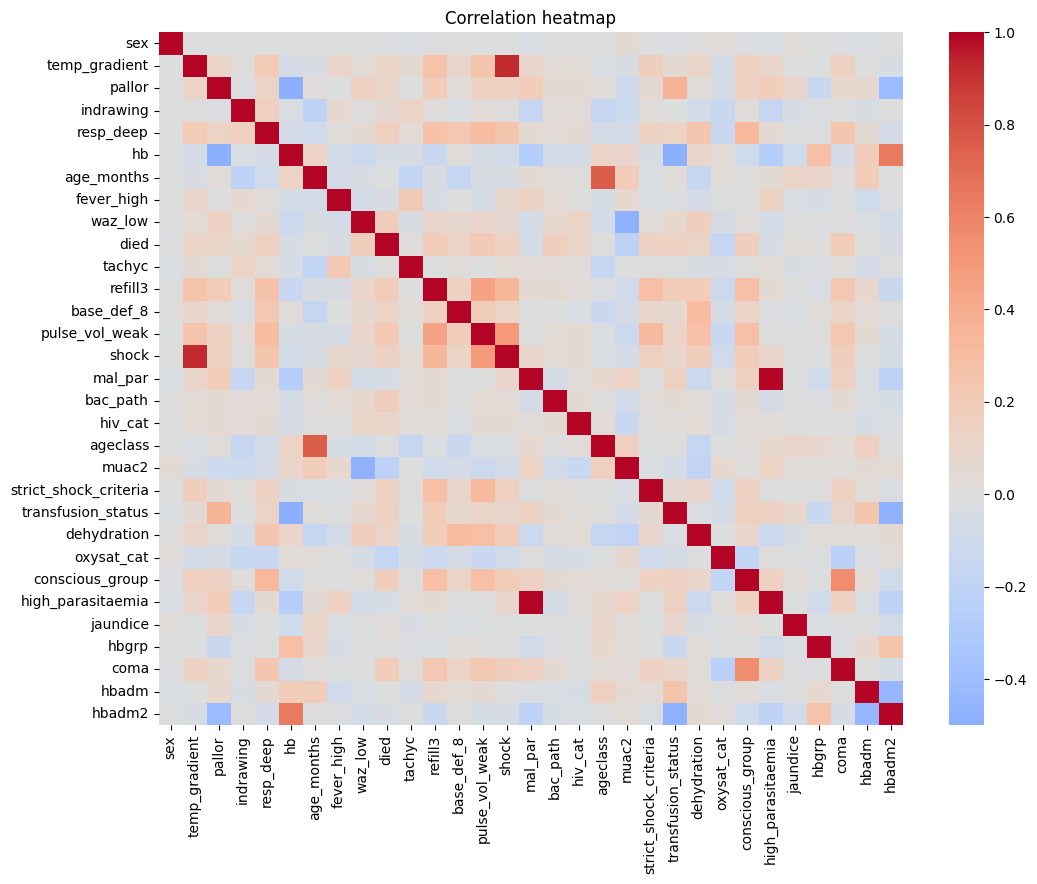

transfusion_status      -0.500171
pallor                  -0.491449
mal_par                 -0.258043
high_parasitaemia       -0.256915
refill3                 -0.144691
waz_low                 -0.127070
jaundice                -0.100422
conscious_group         -0.099393
shock                   -0.081147
fever_high              -0.076847
bac_path                -0.068885
coma                    -0.064122
resp_deep               -0.063404
temp_gradient           -0.062738
hiv_cat                 -0.057403
died                    -0.054116
tachyc                  -0.050849
pulse_vol_weak          -0.048153
strict_shock_criteria   -0.038918
indrawing               -0.023786
sex                     -0.000717
base_def_8               0.024667
oxysat_cat               0.042737
muac2                    0.094401
dehydration              0.101982
ageclass                 0.123954
age_months               0.130895
hbadm                    0.188060
hbgrp                    0.286782
hbadm2        

In [32]:
tmp = df.copy()
for c in tmp.columns:
    if tmp[c].dtype == "object" or str(tmp[c].dtype) == "str":
        tmp[c] = tmp[c].astype("category").cat.codes.replace(-1, np.nan)

plt.figure(figsize=(12, 9))
sns.heatmap(tmp.corr(), cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

tmp.corr()["hb"].sort_values()

**What it shows.** Correlations between all columns, including ones that will be dropped. `hbadm`, `hbadm2` and `hbgrp` correlate with `hb` because they are `hb` in another form, and `transfusion_status` correlates because it is decided after admission. Category codes for text columns are arbitrary, so the signs and sizes for those columns are only a rough guide.

**Decision.** Drop all four, since keeping them would hand the model the answer. Among the bedside signs, `pallor` has the strongest link to `hb`, followed by the malaria columns.

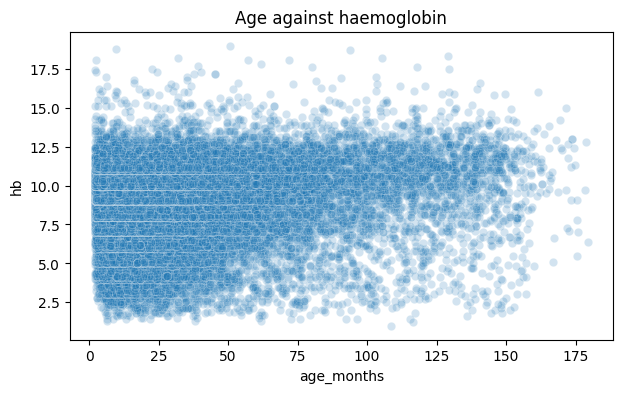

In [33]:
plt.figure(figsize=(7, 4))
sns.scatterplot(x="age_months", y="hb", data=df, alpha=0.2)
plt.title("Age against haemoglobin")
plt.show()

**What it shows.** Haemoglobin against age in months. There is a weak positive trend (correlation about 0.13) with a wide spread at every age.

**Decision.** Keep `age_months` as a numeric feature. Age alone is a weak predictor, so the model needs the other bedside signs as well.

## 3. Choose features and clean the data

In [34]:
drop_cols = [
    "hbadm", "hbadm2", "hbgrp",          # hb in another form
    "died", "transfusion_status",        # known only after admission
    "ageclass",                          # duplicate of age_months
    "hiv_cat", "base_def_8",             # mostly empty
    "high_parasitaemia", "bac_path",     # need a lab
    "conscious_group", "strict_shock_criteria",  # duplicates of coma and shock
]
data = df.drop(columns=drop_cols).copy()
print(data.shape)

(29226, 19)


**Columns dropped and why**

* `hbadm`, `hbadm2`, `hbgrp`: haemoglobin in another form, so they would leak the answer.
* `died`, `transfusion_status`: recorded after admission, so a nurse cannot know them at the bedside.
* `ageclass`: duplicate of `age_months`.
* `hiv_cat`, `base_def_8`: 61% and 44% empty, and both need a lab test.
* `high_parasitaemia`, `bac_path`: a parasite count and a bacterial culture need a lab.
* `conscious_group`: 3,992 missing, and `coma` carries the same idea with only 55 missing.
* `strict_shock_criteria`: a derived rule, while `shock` is the plain bedside sign.

**Kept on purpose.** `mal_par` (a rapid malaria test can be done without a lab) and `oxysat_cat` (a pulse oximeter is a bedside device). That leaves 18 input features.

In [35]:
yes_values = {"yes", "y", "Yes"}
no_values = {"no", "n", "No"}

binary_cols = ["temp_gradient", "pallor", "indrawing", "resp_deep", "fever_high",
               "tachyc", "refill3", "pulse_vol_weak", "shock", "mal_par",
               "dehydration", "jaundice", "coma"]

for c in binary_cols:
    data[c] = data[c].map(lambda v: 1 if v in yes_values else (0 if v in no_values else np.nan))

In [36]:
data["sex"] = data["sex"].map({"male": 1, "female": 0})
data["muac2"] = data["muac2"].map({"muac<=11.5cm": 1, "muac>11.5cm": 0})      # 1 means small arm, a sign of malnutrition
data["oxysat_cat"] = data["oxysat_cat"].map({"Oxysat<90%": 1, "Oxysat>90%": 0})  # 1 means low oxygen

data.isna().sum()

sex                 0
temp_gradient     115
pallor             45
indrawing          43
resp_deep          46
hb                  0
age_months          0
fever_high         56
waz_low           216
tachyc              0
refill3            70
pulse_vol_weak     69
shock              47
mal_par           256
muac2             492
dehydration         0
oxysat_cat          0
jaundice           52
coma               55
dtype: int64

Every yes/no column is now 1 or 0. `sex` is 1 for male, `muac2` is 1 for a small arm circumference (11.5 cm or less), and `oxysat_cat` is 1 for oxygen saturation below 90 percent.

In [37]:
print(data.dtypes)
for c in data.columns.drop(["hb", "age_months"]):
    print(c, sorted(data[c].dropna().unique()))

sex                 int64
temp_gradient     float64
pallor            float64
indrawing         float64
resp_deep         float64
hb                float64
age_months        float64
fever_high        float64
waz_low           float64
tachyc              int64
refill3           float64
pulse_vol_weak    float64
shock             float64
mal_par           float64
muac2             float64
dehydration         int64
oxysat_cat          int64
jaundice          float64
coma              float64
dtype: object
sex [np.int64(0), np.int64(1)]
temp_gradient [np.float64(0.0), np.float64(1.0)]
pallor [np.float64(0.0), np.float64(1.0)]
indrawing [np.float64(0.0), np.float64(1.0)]
resp_deep [np.float64(0.0), np.float64(1.0)]
fever_high [np.float64(0.0), np.float64(1.0)]
waz_low [np.float64(0.0), np.float64(1.0)]
tachyc [np.int64(0), np.int64(1)]
refill3 [np.float64(0.0), np.float64(1.0)]
pulse_vol_weak [np.float64(0.0), np.float64(1.0)]
shock [np.float64(0.0), np.float64(1.0)]
mal_par [np.float64(0.0

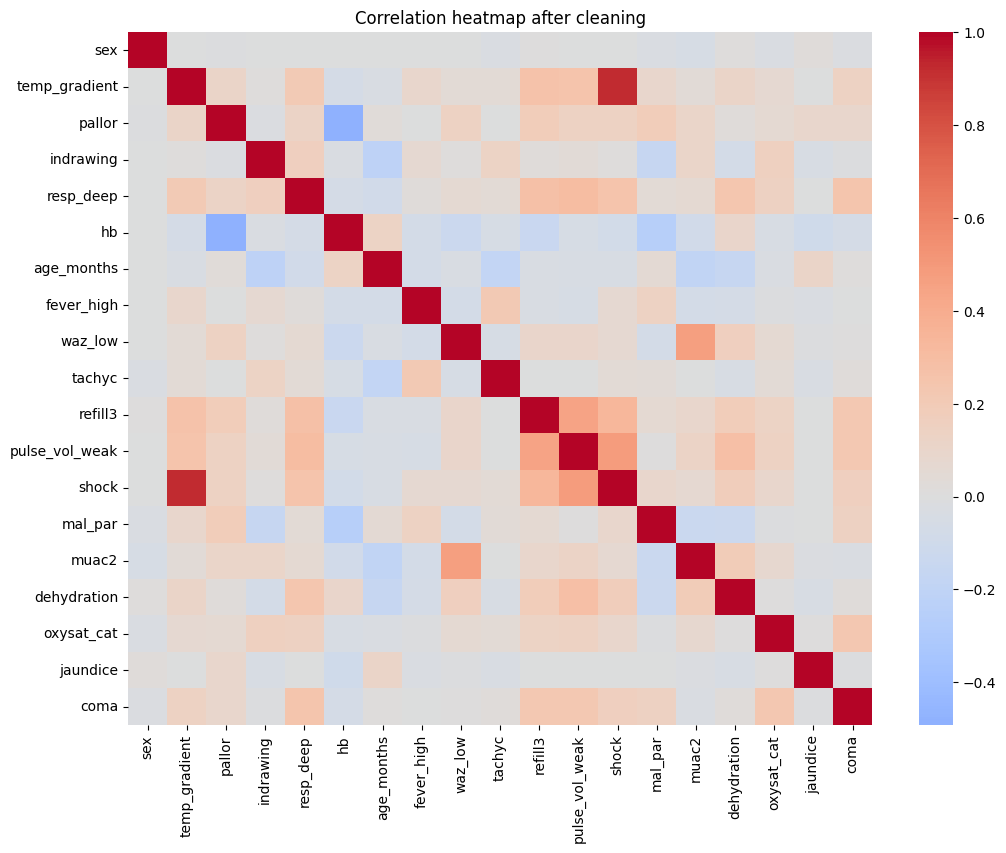

In [38]:
# Correlation heatmap on the cleaned data (only the columns the model will use)
plt.figure(figsize=(12, 9))
sns.heatmap(data.corr(), cmap="coolwarm", center=0)
plt.title("Correlation heatmap after cleaning")
plt.show()

**What it shows.** After cleaning, every remaining column is numeric. `pallor` is the strongest link to `hb`, then the malaria sign `mal_par`, then signs such as `refill3`, `waz_low` and `age_months`. `sex` and `indrawing` are almost unrelated to `hb`.

**Decision.** One pair overlaps strongly: `temp_gradient` and `shock` (correlation about 0.92). Both are kept for now, because the tree models are not harmed by overlapping features, but it means individual linear coefficients should not be over interpreted. Dropping one of them would shorten the app form and is worth testing. All 18 features stay for this version. Gaps are small (under 2 percent of rows) and are filled after the split.

## 4. Split, impute and scale

In [39]:
X = data.drop(columns=["hb"])
y = data["hb"]
print(X.shape, y.shape)

(29226, 18) (29226,)


The features are `X` (18 columns) and the target is `y` (`hb`).

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

SEED = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

imputer = SimpleImputer(strategy="median")   # fills gaps with the training median
scaler = StandardScaler()                    # rescales each feature to mean 0, spread 1

X_train_i = imputer.fit_transform(X_train)   # learn from train only
X_test_i = imputer.transform(X_test)         # apply what was learned
X_train_s = scaler.fit_transform(X_train_i)
X_test_s = scaler.transform(X_test_i)
print(X_train_s.shape, X_test_s.shape)

(23380, 18) (5846, 18)


The data is split first, with one fixed seed (42) and an 80/20 split, so every model is scored on the same 5,846 test rows. The imputer (median) and the scaler are fitted on the training rows only and then applied to the test rows. Fitting them on all the data would let information from the test set influence training, which makes the test score look better than it really is.

## 5. Train and tune the models

In [41]:
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

# What a model scores if it always guesses the average hb (our yardstick)
baseline_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print("Baseline test MSE (always predict the mean):", round(baseline_mse, 3))

def run_sgd(eta0, alpha, epochs, Xa, ya, Xb, yb):
    """Train with partial_fit and record the MSE on both sets after every epoch."""
    model = SGDRegressor(loss="squared_error", penalty="l2", alpha=alpha,
                         learning_rate="constant", eta0=eta0, random_state=SEED)
    rng = np.random.default_rng(SEED)
    ya_arr = np.asarray(ya)
    a_losses, b_losses = [], []
    for _ in range(epochs):
        idx = rng.permutation(len(Xa))                 # reshuffle each epoch
        model.partial_fit(Xa[idx], ya_arr[idx])        # one pass over the data
        a_losses.append(mean_squared_error(ya, model.predict(Xa)))
        b_losses.append(mean_squared_error(yb, model.predict(Xb)))
    return model, a_losses, b_losses

Baseline test MSE (always predict the mean): 5.361


**Baseline.** A model that always guesses the average haemoglobin scores a test MSE of about 5.36. Any useful model must beat this.

In [42]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train_s, y_train, test_size=0.2, random_state=SEED)

trials = []
for eta0 in [0.0001, 0.001, 0.01]:
    for alpha in [0.0001, 0.001, 0.01]:
        _, tr_loss, val_loss = run_sgd(eta0, alpha, 100, X_tr, y_tr, X_val, y_val)
        for ep in [20, 50, 100]:
            trials.append({"eta0": eta0, "alpha": alpha, "epochs": ep,
                           "train_mse": tr_loss[ep - 1], "val_mse": val_loss[ep - 1]})

trials_df = pd.DataFrame(trials).sort_values("val_mse")
trials_df.round(4)

,eta0,alpha,epochs,train_mse,val_mse
1,0.0001,0.0001,50,3.7661,3.7501
4,0.0001,0.0010,50,3.7661,3.7503
7,0.0001,0.0100,50,3.7665,3.7522
0,0.0001,0.0001,20,3.7676,3.7526
3,0.0001,0.0010,20,3.7676,3.7528
14,0.0010,0.0010,100,3.7850,3.7539
11,0.0010,0.0001,100,3.7852,3.7539
17,0.0010,0.0100,100,3.7834,3.7539
6,0.0001,0.0100,20,3.7683,3.7545
2,0.0001,0.0001,100,3.7658,3.7545


**Tuning SGDRegressor.** Trials were scored on a validation slice of the training data, so the test set stayed untouched.

* **Learning rate (`eta0`) mattered most.** At 0.01 the steps were too large and the loss stayed high and unstable (validation MSE about 4.1 to 4.7). At 0.001 and 0.0001 the loss settled near 3.75.
* **Regularisation (`alpha`) barely mattered.** Moving it from 0.0001 to 0.01 changed validation MSE by about 0.002, because there are only 18 features and many rows, so there is little to overfit.
* **Epochs.** With `eta0` of 0.0001 the loss was already flat by 20 epochs, so 50 against 20 differs by only about 0.003. A larger learning rate needed more epochs and still bounced around.

The best trial used `eta0` 0.0001, `alpha` 0.0001 and 50 epochs.

eta0          0.000100
alpha         0.000100
epochs       50.000000
train_mse     3.766145
val_mse       3.750148
Name: 1, dtype: float64


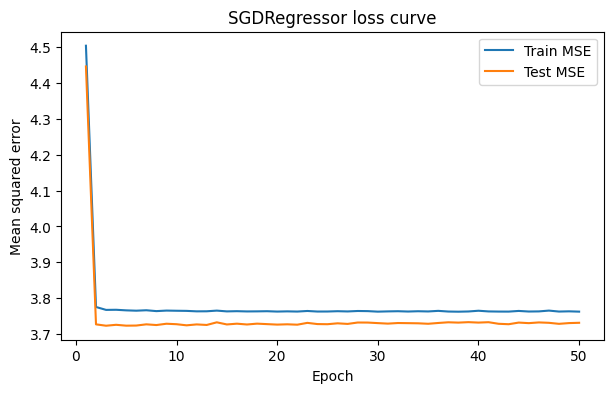

In [43]:
best = trials_df.iloc[0]
print(best)

sgd_final, train_curve, test_curve = run_sgd(best["eta0"], best["alpha"], int(best["epochs"]),
                                             X_train_s, y_train, X_test_s, y_test)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(train_curve) + 1), train_curve, label="Train MSE")
plt.plot(range(1, len(test_curve) + 1), test_curve, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.show()

**Loss curve.** Train and test MSE per epoch for SGDRegressor. Both curves flatten early and end close together (about 3.76 for train and 3.73 for test). The small gap and the high flat level mean the linear model is underfitting: it has learned what a straight line can learn from these signs, and more epochs do not help.

In [44]:
lin = LinearRegression().fit(X_train_s, y_train)

tree = DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=SEED)
tree.fit(X_train_s, y_train)

forest = RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=10,
                               n_jobs=-1, random_state=SEED)
forest.fit(X_train_s, y_train)

models = {"SGDRegressor": sgd_final, "LinearRegression": lin,
          "DecisionTreeRegressor": tree, "RandomForestRegressor": forest}

comparison = pd.DataFrame([
    {"model": name,
     "train_mse": mean_squared_error(y_train, m.predict(X_train_s)),
     "test_mse": mean_squared_error(y_test, m.predict(X_test_s))}
    for name, m in models.items()
]).sort_values("test_mse").round(4)

comparison

,model,train_mse,test_mse
3,RandomForestRegressor,3.1166,3.5844
2,DecisionTreeRegressor,3.4588,3.6682
1,LinearRegression,3.7615,3.7294
0,SGDRegressor,3.7622,3.7311


In [45]:
best_row = comparison.iloc[0]
print(f"Best model by lowest test MSE: {best_row['model']} (test MSE {best_row['test_mse']:.4f})")

Best model by lowest test MSE: RandomForestRegressor (test MSE 3.5844)


## 6. Compare the models and choose the best

**Best model: RandomForestRegressor**, chosen because it has the lowest test MSE (about 3.58). The criterion is test MSE alone, since the test rows were never used for fitting or tuning.

**How the dataset affected each model**

* **SGDRegressor and LinearRegression** score almost the same (about 3.73), because gradient descent converges to the solution the closed form finds directly. Their train and test errors are nearly equal, so they underfit: most features are yes/no signs with weak and overlapping effects, and a straight line cannot capture interactions between them.
* **DecisionTreeRegressor** (depth limited to 8) does better (about 3.67) because it can split on combinations of signs, such as pallor together with age.
* **RandomForestRegressor** does best because averaging many trees captures those interactions while reducing the noise a single tree picks up. Its train MSE is lower than its test MSE (3.12 against 3.58), a mild sign of overfitting that the depth and leaf limits keep small.

**Why it fits the problem.** The task is to rank children by how low their haemoglobin is. The forest gives the most accurate estimate from bedside signs alone, and it needs no extra inputs at prediction time.

**Is the test loss high or low?** The best RMSE is about 1.9 g/dL against about 2.3 for the baseline, so bedside signs explain about a third of the variation. That is useful for ranking children, but too coarse to read as an exact value. To reduce it, I would add features that need a test (a haemoglobin point of care reading), try gradient boosting, and tune the forest more.

## 6b. Compare MSE with Huber loss

The models above were scored with mean squared error. This section scores them again with Huber loss, to check that the choice of best model does not depend on the loss.

In [46]:
# Huber loss: squared error for small mistakes, straight line (absolute error) for big ones.
# HUBER_DELTA is the switch point in g/dL: errors up to 1.0 g/dL are treated like MSE,
# errors above 1.0 g/dL grow more slowly, so a few very wrong children count for less.
HUBER_DELTA = 1.0

def huber_loss(y_true, y_pred, delta=HUBER_DELTA):
    r = np.abs(np.asarray(y_true) - np.asarray(y_pred))          # absolute error per child
    return float(np.mean(np.where(r <= delta,
                                  0.5 * r ** 2,                   # small error: quadratic
                                  delta * (r - 0.5 * delta))))    # large error: linear

# Score every model on both losses, on the same train and test sets as before
rows = []
for name, m in models.items():
    rows.append({
        "model": name,
        "train_mse": mean_squared_error(y_train, m.predict(X_train_s)),
        "test_mse": mean_squared_error(y_test, m.predict(X_test_s)),
        "train_huber": huber_loss(y_train, m.predict(X_train_s)),
        "test_huber": huber_loss(y_test, m.predict(X_test_s)),
    })

metric_comparison = pd.DataFrame(rows).sort_values("test_mse").round(4)
metric_comparison

,model,train_mse,test_mse,train_huber,test_huber
3,RandomForestRegressor,3.1166,3.5844,0.9419,1.0325
2,DecisionTreeRegressor,3.4588,3.6682,1.0128,1.0472
1,LinearRegression,3.7615,3.7294,1.0770,1.0635
0,SGDRegressor,3.7622,3.7311,1.0773,1.0639


,sgd_loss,test_mse,test_huber
0,squared_error,3.7311,1.0639
1,huber (epsilon 0.5),3.7487,1.0603
2,huber (epsilon 1.0),3.7501,1.0610
3,huber (epsilon 2.0),3.7427,1.0615


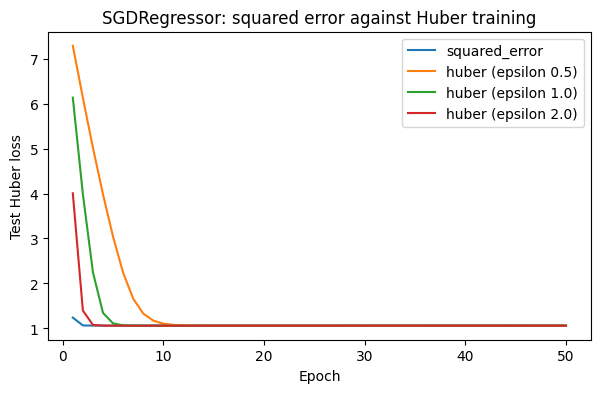

In [47]:
# Train SGD one epoch at a time with a chosen loss, and record the Huber loss per epoch.
# In scikit-learn, epsilon is the Huber switch point in g/dL.
def run_sgd_loss(loss, eta0, alpha, epochs, Xa, ya, Xb, yb, epsilon=HUBER_DELTA):
    model = SGDRegressor(loss=loss, epsilon=epsilon, penalty="l2", alpha=alpha,
                         learning_rate="constant", eta0=eta0, random_state=SEED)
    rng = np.random.default_rng(SEED)
    ya_arr = np.asarray(ya)
    a_losses, b_losses = [], []
    for _ in range(epochs):
        idx = rng.permutation(len(Xa))
        model.partial_fit(Xa[idx], ya_arr[idx])
        a_losses.append(huber_loss(ya, model.predict(Xa)))
        b_losses.append(huber_loss(yb, model.predict(Xb)))
    return model, a_losses, b_losses

# Same learning rate, regularisation and epochs as the best MSE run, so only the loss changes
settings = [("squared_error", None), ("huber", 0.5), ("huber", 1.0), ("huber", 2.0)]
sgd_rows, test_curves = [], {}

for loss, eps in settings:
    m, tr_curve, te_curve = run_sgd_loss(loss, best["eta0"], best["alpha"], int(best["epochs"]),
                                         X_train_s, y_train, X_test_s, y_test,
                                         epsilon=eps if eps is not None else HUBER_DELTA)
    label = loss if eps is None else f"huber (epsilon {eps})"
    test_curves[label] = te_curve
    sgd_rows.append({
        "sgd_loss": label,
        "test_mse": mean_squared_error(y_test, m.predict(X_test_s)),
        "test_huber": huber_loss(y_test, m.predict(X_test_s)),
    })

sgd_loss_comparison = pd.DataFrame(sgd_rows).round(4)
display(sgd_loss_comparison)

# Test Huber loss per epoch for each way of training
plt.figure(figsize=(7, 4))
for label, curve in test_curves.items():
    plt.plot(range(1, len(curve) + 1), curve, label=label)
plt.xlabel("Epoch")
plt.ylabel("Test Huber loss")
plt.title("SGDRegressor: squared error against Huber training")
plt.legend()
plt.show()

**MSE against Huber loss.** Mean squared error squares every mistake, so a child whose haemoglobin is badly wrong counts far more than many children who are slightly wrong. Huber loss behaves like MSE for errors up to 1 g/dL and grows in a straight line beyond that, so a few extreme cases pull the model less. I scored all four models with both losses, and I also trained SGDRegressor with Huber loss at three thresholds (epsilon 0.5, 1.0 and 2.0 g/dL), keeping the learning rate, regularisation and epochs the same so that only the loss changed.

**What the results show.**

* The ranking of the four models is the same under both losses: random forest first, then decision tree, then the two linear models, which are almost tied. The choice of best model does not depend on which loss is used.
* Training SGD with Huber loss changed very little. At epsilon 0.5 it gave a slightly lower test Huber loss (about 1.060 against 1.064) and a slightly higher test MSE (about 3.749 against 3.731). Each loss gives a small edge on its own metric, which is what I would expect.
* Huber values are on a different scale from MSE, so they are compared by ranking, not by size.

**Decision.** I keep test MSE as the criterion for choosing the best model. It is the metric the brief asks for, and for this use case it is the right one, because the costly mistakes are large misses on the sickest children, and MSE punishes exactly those. Huber loss would be a better choice if some haemoglobin records were data entry errors, but the values here run from 1 to 19 g/dL and the low ones are real patients that the tool exists to find.

## 6c. Which features matter most

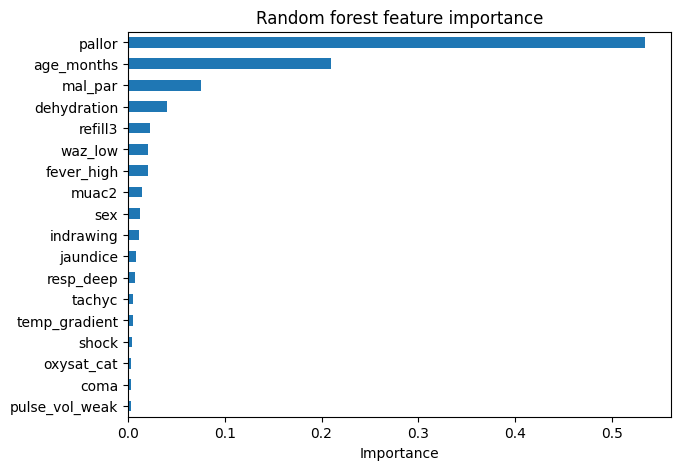

pallor            0.534
age_months        0.210
mal_par           0.075
dehydration       0.041
refill3           0.023
waz_low           0.021
fever_high        0.020
muac2             0.014
sex               0.012
indrawing         0.011
jaundice          0.008
resp_deep         0.007
tachyc            0.005
temp_gradient     0.005
shock             0.004
oxysat_cat        0.003
coma              0.003
pulse_vol_weak    0.003
dtype: float64

In [48]:
# Which features matter most for hb (random forest importance)
importances = pd.Series(forest.feature_importances_, index=X.columns).sort_values(ascending=False)
ax = importances.plot(kind="barh", figsize=(7, 5))
ax.invert_yaxis()
plt.title("Random forest feature importance")
plt.xlabel("Importance")
plt.show()
importances.round(3)

**Which features matter most.** `pallor` carries about half of the importance (0.53), followed by `age_months` (0.21) and the malaria sign `mal_par` (0.08). `dehydration`, `refill3`, `waz_low` and `fever_high` add small amounts, and signs such as `shock`, `coma` and `oxysat_cat` contribute almost nothing on their own.

## 7. Required scatter plots

Strongest feature: pallor


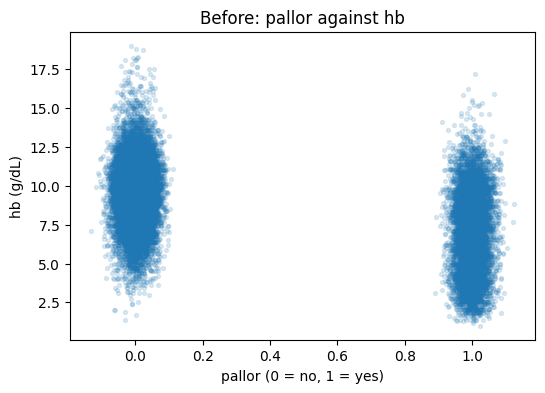

In [49]:
top_feature = data.corr()["hb"].drop("hb").abs().idxmax()
print("Strongest feature:", top_feature)

plot_df = data[[top_feature, "hb"]].dropna()
jitter = np.random.default_rng(SEED).normal(0, 0.03, len(plot_df))   # nudges 0 and 1 apart so points do not stack

plt.figure(figsize=(6, 4))
plt.scatter(plot_df[top_feature] + jitter, plot_df["hb"], alpha=0.15, s=8)
plt.xlabel(top_feature + " (0 = no, 1 = yes)")
plt.ylabel("hb (g/dL)")
plt.title("Before: " + top_feature + " against hb")
plt.show()

**Before.** The strongest feature, `pallor`, is a yes/no sign, so the points form two columns (0 and 1). A little random sideways jitter is added to the plot only, so the points do not sit on top of each other. Children with pallor sit lower on `hb`, with a wide spread in both groups.

Slope: -2.620730448690048 Intercept: 9.630194074629664


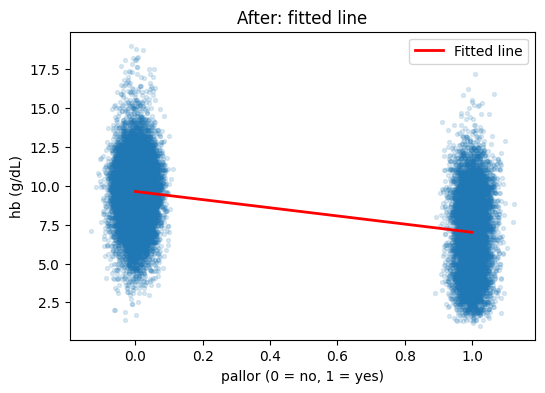

In [23]:
one_feature_model = LinearRegression().fit(plot_df[[top_feature]], plot_df["hb"])
xs = np.array([[0], [1]])
ys = one_feature_model.predict(pd.DataFrame(xs, columns=[top_feature]))
print("Slope:", one_feature_model.coef_[0], "Intercept:", one_feature_model.intercept_)

plt.figure(figsize=(6, 4))
plt.scatter(plot_df[top_feature] + jitter, plot_df["hb"], alpha=0.15, s=8)
plt.plot(xs, ys, color="red", linewidth=2, label="Fitted line")
plt.xlabel(top_feature + " (0 = no, 1 = yes)")
plt.ylabel("hb (g/dL)")
plt.title("After: fitted line")
plt.legend()
plt.show()

**After.** The red line comes from a one feature linear regression made for this plot only. With a yes/no feature the line simply joins the two group averages. The slope of about 2.62 g/dL downward says children with pallor average about 2.6 g/dL lower haemoglobin. The wide spread around the line shows why one sign is not enough and the full model uses 18.

## 8. Save the best model and predict

In [24]:
def clean_raw(raw):
    out = raw.drop(columns=drop_cols, errors="ignore").copy()
    for c in binary_cols:
        out[c] = out[c].map(lambda v: 1 if v in yes_values else (0 if v in no_values else np.nan))
    out["sex"] = out["sex"].map({"male": 1, "female": 0})
    out["muac2"] = out["muac2"].map({"muac<=11.5cm": 1, "muac>11.5cm": 0})
    out["oxysat_cat"] = out["oxysat_cat"].map({"Oxysat<90%": 1, "Oxysat>90%": 0})
    return out

print(clean_raw(df).equals(data))

True


`clean_raw` repeats the cleaning steps in one function. The API reuses it when `/retrain` receives a raw CSV, so the notebook and the API clean data in exactly the same way. It returns `True` when it reproduces `data`.

In [25]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.base import clone

best_name = comparison.iloc[0]["model"]
print("Best model:", best_name)

final_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", clone(models[best_name])),
])
final_pipeline.fit(X_train, y_train)   # raw (cleaned) rows in, so the file is self contained

test_mse = mean_squared_error(y_test, final_pipeline.predict(X_test))
print("Pipeline test MSE:", round(test_mse, 4))   # should match the table

joblib.dump(final_pipeline, "best_model.pkl")

Best model: RandomForestRegressor
Pipeline test MSE: 3.5844


['best_model.pkl']

The best model is wrapped with its imputer and scaler in one scikit-learn Pipeline and saved with joblib. It takes raw cleaned rows, so the file is self contained. The test MSE printed here matches the comparison table.

In [26]:
def predict_one_row(row_df, path="best_model.pkl"):
    model = joblib.load(path)
    return float(model.predict(row_df)[0])

sample = X_test.iloc[[0]]
print("Predicted hb:", round(predict_one_row(sample), 2), "| Actual hb:", y_test.iloc[0])

Predicted hb: 4.26 | Actual hb: 5.6


This function loads the saved file and predicts `hb` for one row of the test set. The API reuses the same idea.

## 9. Export for the API

The model and the cleaned training data go into `summative/API`. The forest cannot learn from new rows incrementally, so `/retrain` refits on the original data plus the new rows, which needs the training data on the server.

In [27]:
from google.colab import files

data.to_csv("training_data.csv", index=False)   # cleaned rows, 18 features plus hb
files.download("best_model.pkl")
files.download("training_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>